# **Capitolo 4. Analisi del Dataset delle Recensioni Clienti**

Terminata l’analisi esplorativa sul contenuto testuale, l’indagine si sposta sull’**estrazione della conoscenza** tramite tecniche di NLP, con l’obiettivo primario di **analizzare il tono emotivo espresso nelle recensioni** e **verificarne la coerenza** con la valutazione numerica assegnata dagli utenti. L’analisi condurrà successivamente alla costruzione di un vero e proprio **indice di coerenza tra sentiment e voto**, per offrire una chiave di lettura più fine sulla reale soddisfazione dei consumatori nel mercato. 

> Questo terzo e ultimo notebook riguardante le procedure descritte nel quarto capitolo, si occupa della sentiment analysis e della costruzione dell'indice di coerenza percettiva (*l'intero paragrafo 4.3 con annesse sottosezioni, quindi fino alla fine del capitolo*). 

## **4.3. Sentiment Analysis**

In questo terzo notebook, il progetto evolve verso l'**estrazione automatizzata della conoscenza** proveniente dal contenuto testuale delle recensioni.

In questa fase preparatoria configuriamo l'ambiente di lavoro e carichiamo i dati di studio, ottenuti al termine del notebook precedente `2_text_eda__recensioni.ipynb`.

In [ ]:
import os
import re
import time
import pandas as pd
import numpy as np
import emoji
import matplotlib.pyplot as plt
from tqdm import tqdm
from pathlib import Path
import matplotlib.gridspec as gridspec
from IPython.display import display, HTML
from transformers import pipeline as hf_pipeline
from scipy.stats import spearmanr, kendalltau
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Allineamento della directory di lavoro
while not os.path.exists("Circular Second Hand") and os.getcwd() != os.path.dirname(os.getcwd()):
    os.chdir("..")

print(f"Jupyter è allineato. Cartella di lavoro attuale:\n{os.getcwd()}.\n")


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [2]:
# Caricamento file di input (file csv generato dal notebook precedente, 2_text_eda__recensioni.ipynb)
display(HTML("<h3>Caricamento del dataset di input</h3>"))
file_input = r'Circular Second Hand\Analisi\Analisi - Recensioni\Risultati Analisi - Recensioni\2_text_eda__recensioni.csv'
df = pd.read_csv(file_input, index_col='ID Recensione')

# Estrazione automatica del nome del file
nome_file = file_input.split('\\')[-1]
display(HTML(f"File <b>{nome_file}</b> caricato correttamente: righe totali <b>{len(df):,}</b>; colonne totali <b>{df.shape[1]}</b>; indice <code>ID Recensione</code>."))

# Controllo e normalizzazione della colonna Raccomandato
# Il passaggio attraverso il CSV converte il booleano nullable in stringhe "True"/"False". Lo riportiamo al tipo corretto prima di procedere.
# Pulizia, range e dtypes di tutti gli altri campi sono garantiti dal notebook 1.
df['Raccomandato'] = (df['Raccomandato'].map({'True': True, 'False': False, True: True, False: False}).astype(pd.BooleanDtype()))
racc = df['Raccomandato'].value_counts(dropna=False)
display(HTML(f"<code>Raccomandato</code> normalizzato: True <b>{racc.get(True,0):,}</b>; False <b>{racc.get(False,0):,}</b>; NaN <b>{df['Raccomandato'].isna().sum():,}</b>."))

# Creazione dei due corpus
# Le analisi testuali e numeriche operano su basi dati diverse per scelta metodologica consapevole.
# Forzarle sullo stesso sottoinsieme significherebbe perdere i dati numerici delle recensioni prive di testo.
display(HTML("<h3 style='margin-bottom: 0;'>Creazione di due corpus per analisi testuali e numeriche</h3>"))
df_testo = df[df['Testo Tradotto'].notna()].copy()
df_numerico = df.copy()

display(HTML(f"""<ul style='margin-top: 0;'>
        <li><code>df_numerico</code>: <b>{df_numerico.shape[0]:,}</b> righe e <b>{df_numerico.shape[1]}</b> colonne.</li>
        <li><code>df_testo</code>: <b>{df_testo.shape[0]:,}</b> righe e <b>{df_testo.shape[1]}</b> colonne.</li></ul>"""))

### **4.3.1. Estrazione del sentiment dalle emoji**

Le **emoji** rappresentano **segnali paralinguistici**, ovvero elementi che non fanno parte della lingua scritta in senso stretto ma che trasmettono informazioni emotive spesso molto forti e immediate. Si adotta un approccio strutturato che separa le emoji dal testo, trattandole come una fonte informativa autonoma. Invece di assegnare manualmente etichette arbitrarie (positivo/negativo), si utilizza un approccio data-driven basato sul dataset **Emoji Sentiment Ranking** (Kralj Novak et al., 2015). Questo consente di attribuire a ciascuna emoji uno **score continuo compreso tra -1 e +1**, rendendo la modellazione più realistica, oggettiva e meno soggetta a bias interpretativi.

In [3]:
display(HTML("<h3>Emoji Sentiment Ranking (Kralj Novak et al., 2015)</h3>"))

url_novak_mirror = "https://raw.githubusercontent.com/fsteuber/emoji_sentiment/master/Emoji_Sentiment_Data_v1.0.csv"
modificatori = ['\U0001F3FB', '\U0001F3FC', '\U0001F3FD','\U0001F3FE', '\U0001F3FF', '\uFE0F']

def sterilizza_emoji(e):
    if not isinstance(e, str): return e
    for m in modificatori:
        e = e.replace(m, '')
    return e

try:
    df_novak = pd.read_csv(url_novak_mirror)

    # Calcolo Sentiment Score Ufficiale
    df_novak['Novak_Score'] = (df_novak['Positive'] - df_novak['Negative']) / df_novak['Occurrences']

    # Creazione del dizionario
    novak_lexicon = {sterilizza_emoji(k): v for k, v in zip(df_novak['Emoji'], df_novak['Novak_Score'])}

    display(HTML(f"Lexicon di Novak scaricato e normalizzato! Caricate {len(novak_lexicon)} emoji validate empiricamente."))

except Exception as e:
    display(HTML(f"Errore nel caricamento: {e}."))

# Test di verifica
emoji_test = ['😍', '👍', '❤️', '😊', '😡', '👎', '📦', '😭', '🚚', '🎉']
demo_novak = [{'Emoji': e, 'Score (Novak)': round(novak_lexicon.get(sterilizza_emoji(e), 0.0), 3)} for e in emoji_test]

display(pd.DataFrame(demo_novak).style.background_gradient(cmap='RdYlGn', vmin=-1, vmax=1).format(precision=3))

,Emoji,Score (Novak)
0,😍,0.678
1,👍,0.522
2,❤️,0.746
3,😊,0.645
4,😡,-0.173
5,👎,-0.190
6,📦,0.250
7,😭,-0.093
8,🚚,-0.100
9,🎉,0.740


In [ ]:
# APPLICAZIONE DELLO SCORING
# Funzione che estrae le emoji dal testo e ne calcola lo score e i conteggi tramite il lexicon di Novak
def estrai_feature_emoji(testo):
    if pd.isna(testo):
        return [], 0, 0, 0, 0.0

    testo_str = str(testo)

    # Estrazione delle emoji presenti
    em_raw = [e['emoji'] for e in emoji.emoji_list(testo_str)]
    em_clean = []

    for e in em_raw:
        for m in modificatori:
            e = e.replace(m, '')
        if e:
            em_clean.append(e)

    pos_count = neg_count = neu_count = 0
    score_totale = 0.0

    for e in em_clean:
        score = novak_lexicon.get(e, 0.0)
        score_totale += score
        if score > 0.1:
            pos_count += 1
        elif score < -0.1:
            neg_count += 1
        else:
            neu_count += 1

    return em_clean, pos_count, neg_count, neu_count, round(score_totale, 4)

tqdm.pandas(desc="Estrazione Emoji & Scoring Novak", colour='green')
risultati = df_testo['Testo Tradotto'].progress_apply(estrai_feature_emoji)

df_testo['Lista_Emoji']       = [r[0] for r in risultati]
df_testo['Emoji_Pos']         = [r[1] for r in risultati]
df_testo['Emoji_Neg']         = [r[2] for r in risultati]
df_testo['Emoji_Neu']         = [r[3] for r in risultati]
df_testo['Emoji_Score_Novak'] = [r[4] for r in risultati]

# Riepilogo metriche
ha_emoji = df_testo['Lista_Emoji'].apply(lambda x: len(x) > 0)
display(HTML(f"""<h4>Feature Extraction completata:</h4>
             <ul> <li> Righe nel corpus testuale: <b>{len(df_testo):,}</b>.</li>
             <li> Recensioni contenenti almeno un'emoji: <b>{ha_emoji.sum():,}</b> ({ha_emoji.mean()*100:.1f}%).</li></ul>"""))

# Ispezione visiva: recensioni con emozioni miste (contenenti sia emoji positive che negative)
recensioni_miste = df_testo[(df_testo['Emoji_Pos'] > 0) & (df_testo['Emoji_Neg'] > 0)]

if not recensioni_miste.empty:
    display(HTML(f"<h4>Trovate {len(recensioni_miste)} recensioni con emozioni sia positive che negative:</h4>"))
    with pd.option_context('display.max_colwidth', None):
        display(recensioni_miste[['Testo Tradotto', 'Emoji_Pos', 'Emoji_Neg', 'Emoji_Score_Novak']].head(3))
else:
    display(HTML("<h4>Ispezione a campione:</h4>"))
    with pd.option_context('display.max_colwidth', None):
        display(df_testo[df_testo['Emoji_Score_Novak'] != 0.0][['Testo Tradotto', 'Lista_Emoji', 'Emoji_Score_Novak']].head(3))


### [Output rimosso per tutela della privacy e riservatezza commerciale]

### **4.3.2. Pre-processing e modellazione del sentiment**

I modelli impiegati di seguito (BERT italiano 'cased', FEEL-IT, Llama 3) sono addestrati su testo naturale e sfruttano attivamente maiuscole e punteggiatura come segnali di intensità emotiva. **Qualsiasi normalizzazione aggressiva** (lowercase, rimozione di punteggiatura, stopword, lemmatizzazione) **degraderebbe l'input**, privando i modelli dei segnali su cui sono stati addestrati. Il pre-processing si limita quindi a due soli interventi necessari: **rimozione delle emoji** (già estratte come canale informativo separato nel Paragrafo 2); **deduplicazione della ripetizione titolo/corpo**, artefatto della concatenazione effettuata nel notebook precedente.

In [ ]:
# PRE-PROCESSING
display(HTML("<h3>Pre-processing: costruzione del corpus per l'analisi del sentiment</h3>"))

# Soglia minima: si interviene solo su blocchi ripetuti di almeno 3 parole, per non intaccare ripetizioni volontarie e semanticamente rilevanti (es. "molto molto bello").
MIN_PAROLE_BLOCCO = 3

# Versione normalizzata usata solo per il confronto, mai per l'output
def _normalizza_per_confronto(parole: list[str]) -> list[str]:
    return [re.sub(r'\W+', '', p.lower()) for p in parole]

# La seguente funzione rimuove la ripetizione iniziale generata dalla concatenazione 'Titolo + Corpo'.
# Il confronto è insensibile a maiuscole e punteggiatura, ma il testo restituito resta rigorosamente naturale.
def deduplica_testo(testo: str) -> str:
    if not isinstance(testo, str) or testo.strip() == "":
        return ""

    parole = testo.split()
    n = len(parole)
    if n < MIN_PAROLE_BLOCCO * 2:
        return testo

    parole_cmp = _normalizza_per_confronto(parole)

    # Si cerca il blocco ripetuto più lungo possibile (dal più lungo al più corto), così da rimuovere l'intero titolo e non solo una sua porzione iniziale.
    for lunghezza in range(n // 2, MIN_PAROLE_BLOCCO - 1, -1):
        if parole_cmp[:lunghezza] == parole_cmp[lunghezza:lunghezza * 2]:
            return " ".join(parole[lunghezza:])

    return testo

# Passo 1: rimozione delle emoji (il testo resta naturale)
def togli_emoji(testo: str) -> str:
    if pd.isna(testo):
        return ""
    return " ".join(emoji.replace_emoji(str(testo), replace=' ').split()).strip()

tqdm.pandas(desc="Rimozione emoji", colour="#99e699")
df_testo['Testo_Senza_Emoji'] = df_testo['Testo Tradotto'].progress_apply(togli_emoji)

# Passo 2: deduplicazione titolo/corpo
tqdm.pandas(desc="Deduplicazione", colour="#006622")
df_testo['Corpus_Sentiment'] = df_testo['Testo_Senza_Emoji'].progress_apply(deduplica_testo)

# Maschera dei testi valutabili, riutilizzata in tutte le fasi successive
mask_valutabili = df_testo['Corpus_Sentiment'].str.strip() != ""

# Riepilogo
n_validi = mask_valutabili.sum()
n_ghost  = len(df_testo) - n_validi
n_dedup  = (df_testo['Corpus_Sentiment'] != df_testo['Testo_Senza_Emoji']).sum()

display(HTML(f"""<ul>
    <li>Righe totali: <b>{len(df_testo):,}</b>.</li>
    <li>Testi validi per i modelli di sentiment: <b>{n_validi:,}</b>.</li>
    <li><i>Ghost review</i> (sole emoji, nessun testo residuo): <b>{n_ghost:,}</b>.</li>
    <li>Recensioni su cui è intervenuta la deduplicazione: <b>{n_dedup:,}</b> ({n_dedup/len(df_testo)*100:.1f}%).</li>
    </ul>"""))

# Ispezione: solo casi in cui la deduplicazione ha effettivamente agito
display(HTML("<h4>Ispezione: casi di deduplicazione effettiva</h4>"))
dedup_attiva = df_testo[df_testo['Corpus_Sentiment'] != df_testo['Testo_Senza_Emoji']]
if not dedup_attiva.empty:
    with pd.option_context('display.max_colwidth', 90):
        display(dedup_attiva[['Testo_Senza_Emoji', 'Corpus_Sentiment']].sample(min(10, len(dedup_attiva)), random_state=42))
else:
    display(HTML("<p><i>Nessuna duplicazione rilevata.</i></p>"))

Deduplicazione: 100%|██████████| 97540/97540 [00:01<00:00, 61310.83it/s]


,Testo_Senza_Emoji,Corpus_Sentiment
ID Recensione,,
38351286-3yoi-tIT2-0220-703T06161400,Divertente e facile da montare Divertente e facile da montare,Divertente e facile da montare
46673777-8yoi-tIT2-0230-502T12381200,Perfetto per le mie esigenze Perfetto per le mie esigenze,Perfetto per le mie esigenze
30489969-1yoi-tIT2-0211-020T14034200,Facile nell’utilizzo e ottima resa Facile nell’utilizzo e ottima resa,Facile nell’utilizzo e ottima resa
49752207-2yoi-tIT2-0230-901T08562100,Buon rapporto qualità/prezzo Buon rapporto qualità/prezzo,Buon rapporto qualità/prezzo
50666900-7yoi-tIT2-0231-002T12191400,"Ottime, fanno davvero scena Ottime, fanno davvero scena","Ottime, fanno davvero scena"
22884790-3yoi-tIT2-0210-126T20441900,Buon rapporto qualità preZzo Buon rapporto qualità preZzo,Buon rapporto qualità preZzo
33640585-7yoi-tIT2-0220-210T13072300,Pratico e funzionale Pratico e funzionale proprio quello che cercavo come parta TV fa ...,Pratico e funzionale proprio quello che cercavo come parta TV fa la sua figura ed è fa...
40141463-5yoi-tIT2-0220-911T15334100,Una cornice senza vetro Una cornice senza vetro,Una cornice senza vetro
51233504-9yoi-tIT2-0231-013T21310300,"Mi serviva più spazio per Mi serviva più spazio per riporre i piatti e, non sembra ma ...","Mi serviva più spazio per riporre i piatti e, non sembra ma è molto robusto. Ho avuto ..."


-> **VADER: una baseline deliberatamente inadeguata**

VADER (Valence Aware Dictionary and sEntiment Reasoner; Hutto e Gilbert, 2014) è un modello lexicon-based: dispone di un vocabolario di parole associate a punteggi di polarità e, per ogni frase, individua i termini presenti nel dizionario combinandone i punteggi. Il limite strutturale del modello, nell'attuale contesto, è di natura linguistica.

In [ ]:
# VADER
display(HTML("<h3>VADER: baseline lexicon-based (lingua inglese)</h3>"))

vader = SentimentIntensityAnalyzer()

display(HTML(f"""<ul>
    <li>Righe totali: <b>{len(df_testo):,}</b>.</li>
    <li>Righe valutabili dai modelli di sentiment: <b>{mask_valutabili.sum():,}</b>.</li>
    <li>Ghost review escluse (score = NaN): <b>{(~mask_valutabili).sum():,}</b>.</li></ul>"""))

def calcola_vader(testo: str) -> float:
    return round(vader.polarity_scores(testo)['compound'], 4)

tqdm.pandas(desc="VADER — scoring", colour="#9d522c")

df_testo['Sentiment_VADER'] = np.nan
df_testo.loc[mask_valutabili, 'Sentiment_VADER'] = (df_testo.loc[mask_valutabili, 'Corpus_Sentiment'].progress_apply(calcola_vader))

# Diagnostica linguistica: quanta parte del corpus VADER riesce effettivamente a "vedere"?
lexicon_vader = set(vader.lexicon.keys())

campione_diag = df_testo.loc[mask_valutabili].sample(5000, random_state=42)
parole_corpus = [p.lower().strip(".,;:!?\"'()") for t in campione_diag['Corpus_Sentiment'] for p in t.split()]
parole_riconosciute = [p for p in parole_corpus if p in lexicon_vader]
copertura = len(parole_riconosciute) / len(parole_corpus) * 100

display(HTML(f"""<h4>Diagnostica: copertura del lexicon VADER sul corpus italiano</h4> <ul>
      <li>Parole analizzate (campione di 5.000 recensioni): <b>{len(parole_corpus):,}</b>.</li>
      <li>Parole riconosciute dal lexicon di VADER: <b>{len(parole_riconosciute):,}</b>.</li>
      <li><b>Copertura: {copertura:.2f}%</b> del vocabolario del corpus.</li> </ul>"""))

# Distribuzione: calcolata SOLO sulle righe valutabili
scores = df_testo.loc[mask_valutabili, 'Sentiment_VADER']
n_tot = len(scores)
n_pos = (scores >  0.05).sum()
n_neg = (scores < -0.05).sum()
n_neu = ((scores >= -0.05) & (scores <= 0.05)).sum()

display(HTML(f"""<h4>Distribuzione degli score VADER (su {n_tot:,} righe valutabili)</h4>
    <ul>
      <li>Positivi (compound &gt; 0.05): <b>{n_pos:,}</b> ({n_pos/n_tot*100:.1f}%).</li>
      <li>Neutri: <b>{n_neu:,}</b> ({n_neu/n_tot*100:.1f}%).</li>
      <li>Negativi (compound &lt; -0.05): <b>{n_neg:,}</b> ({n_neg/n_tot*100:.1f}%).</li>
      <li>Media: <b>{scores.mean():.3f}</b> | Mediana: <b>{scores.median():.3f}</b>.</li>
    </ul>"""))

# Correlazione con il voto: solo righe con score E voto entrambi presenti
df_testo['Voto_Num'] = pd.to_numeric(df_testo['Voto Generale Recensione'], errors='coerce')
df_corr = df_testo.dropna(subset=['Sentiment_VADER', 'Voto_Num'])
rho_vader, p_vader = spearmanr(df_corr['Sentiment_VADER'], df_corr['Voto_Num'])

display(HTML(f"""<h4>Correlazione con il Voto Generale</h4>
    <ul><li>Spearman ρ = <b>{rho_vader:.4f}</b> (p-value = {p_vader:.2e}), su <b>{len(df_corr):,}</b> osservazioni.</li></ul>"""))

# Ispezione dei fallimenti più marcati: recensioni con score VADER estremo ma voto opposto
display(HTML("<h4>Ispezione dei casi di fallimento più marcati</h4>"))
fallimenti_pos = df_corr[(df_corr['Sentiment_VADER'] > 0.7) & (df_corr['Voto_Num'] <= 2)].nlargest(2, 'Sentiment_VADER')
fallimenti_neg = df_corr[(df_corr['Sentiment_VADER'] < -0.7) & (df_corr['Voto_Num'] >= 4)].nsmallest(2, 'Sentiment_VADER')
with pd.option_context('display.max_colwidth', 120):
    display(pd.concat([fallimenti_pos, fallimenti_neg])[['Corpus_Sentiment', 'Voto_Num', 'Sentiment_VADER']])

VADER — scoring: 100%|██████████| 97240/97240 [00:03<00:00, 26650.82it/s]


,Corpus_Sentiment,Voto_Num,Sentiment_VADER
ID Recensione,,,
10594313-08bv-itIT-2019-083008581900,"Assemblaggio da rivedere Il cassetto in sé non è male, le guide sono fluide e appare discretamente solido. Il punto ...",2,0.8805
43098678-6yoi-tIT2-0230-110T07044600,"Cuscino con imbottitura molto dura. L ho acquistato per sostituire il cuscino, ma l imbottitura dura non dà benefici...",1,0.8668
564494c3-0d83-454b-b04d-aa35d2c94453,Mensola LACK: Stile Minimalista e Prezzo Accessibile Ho acquistato la mensola LACK per la cameretta e sono molto sod...,5,-0.8442
01776200-7cd4-4554-8a9b-f9764c31a88b,Buon materasso Si dorme bene! Ce l’abbiamo da circa 3 mesi e non abbiamo problemi di nessun tipo. la consistenza com...,4,-0.8309


### **4.3.3. Dai Dizionari ai Transformer: BERT e FEEL-IT**

I limiti osservati con VADER rendono evidente un punto fondamentale: leggere il testo parola per parola non è sufficiente, perché il significato di una frase dipende dal contesto, cioè da come le parole si combinano tra loro. Per superare questo limite è necessario migrare da un modello rule-based a un **modello context-aware**, cioè in grado di interpretare l'intera frase contemporaneamente. Questa capacità è introdotta dai modelli della famiglia **Transformer** (Vaswani et al., 2017), l'architettura neurale che ha rivoluzionato il Natural Language Processing. 

-> **BERT: due strategie di estrazione dello score**

Il modello scelto è BERT (Bidirectional Encoder Representations from Transformers; Devlin et al., 2019). Si utilizza una versione pre-addestrata e ottimizzata per la lingua italiana (`neuraly/bert-base-italian-cased-sentiment`): il modello è stato prima allenato su grandi quantità di testo (fase di pre-training) e successivamente specializzato (fine-tuning) per il task di sentiment analysis a tre classi (positive, neutral, negative). L'implementazione avviene tramite la libreria `Hugging Face Transformers` (Wolf et al., 2020). Si confrontano due strategie:

1. Strategia 1 — Hard labeling: utilizza il solo output standard del modello, la classe dominante e la sua probabilità. Se la classe vincente è positive, lo score è $+P(pos)$; se è negative, $-P(neg)$; se è neutral, lo score è posto a zero. 

2. Strategia 2 — Soft labeling: sfrutta l'intera distribuzione di probabilità, assegnando a ciascuna classe il proprio valore naturale sulla scala di polarità ($+1$ alla classe positiva, $0$ alla neutra, $-1$ alla negativa) e calcolando il valore atteso del sentiment $Score = (+1) \cdot P(pos) + 0 \cdot P(neu) + (-1) \cdot P(neg) = P(pos) - P(neg).$

In [ ]:
# DUE STRATEGIE A CONFRONTO DI BERT
display(HTML("<h3>Confronto BERT Hard vs BERT Soft (sottocampione stratificato)</h3>"))

MODELLO_BERT = "neuraly/bert-base-italian-cased-sentiment"

# Sottocampione stratificato: 200 righe per ciascun livello di voto
df_validi = df_testo[mask_valutabili & df_testo['Voto_Num'].notna()].copy()

N_PER_VOTO = 200
df_sub = pd.concat([g.sample(min(len(g), N_PER_VOTO), random_state=42) for _, g in df_validi.groupby('Voto_Num')]).copy()

display(HTML(f"<p>Sottocampione: <b>{len(df_sub):,}</b> righe ({df_sub.groupby('Voto_Num').size().to_dict()}).</p>"))

# Una sola pipeline con top_k=None: restituisce le probabilità di TUTTE le classi.
# Da questa singola inferenza si ricavano entrambi gli score (Hard e Soft), garantendo che il confronto avvenga sugli stessi identici output del modello.
# truncation=True + max_length=512: il troncamento avviene sui TOKEN (limite reale di BERT), non sui caratteri, evitando di scartare testo utile.
pipe = hf_pipeline("sentiment-analysis", model=MODELLO_BERT, device=-1, top_k=None, truncation=True, max_length=512)
testi = df_sub['Corpus_Sentiment'].tolist()

# Inferenza in batch (molto più efficiente del riga-per-riga)
output = []
BATCH = 32
for i in tqdm(range(0, len(testi), BATCH), desc="BERT — inferenza", colour="#04752A"):
    output.extend(pipe(testi[i:i + BATCH]))

# Estrazione delle probabilità delle tre classi
prob = pd.DataFrame([{r['label'].lower(): r['score'] for r in riga} for riga in output], index=df_sub.index)
df_sub['P_pos'] = prob.get('positive', 0.0)
df_sub['P_neu'] = prob.get('neutral',  0.0)
df_sub['P_neg'] = prob.get('negative', 0.0)

# Strategia 1 — BERT Hard (hard labeling): solo la classe vincente
classe_vincente = prob[['positive', 'neutral', 'negative']].idxmax(axis=1)
prob_vincente   = prob[['positive', 'neutral', 'negative']].max(axis=1)

df_sub['BERT_Hard'] = np.select([classe_vincente == 'positive', classe_vincente == 'negative'], [prob_vincente, -prob_vincente], default=0.0).round(4)

# Strategia 2 — BERT Soft (score atteso): valore atteso della scala di polarità
# E[S] = (+1)*P(pos) + 0*P(neu) + (-1)*P(neg) = P(pos) - P(neg)
df_sub['BERT_Soft'] = (df_sub['P_pos'] - df_sub['P_neg']).round(4)

# Confronto
df_sub['Delta'] = (df_sub['BERT_Soft'] - df_sub['BERT_Hard']).abs()
diff_media = df_sub['Delta'].mean()
diff_max   = df_sub['Delta'].max()
n_disaccordo = (df_sub['Delta'] > 0.25).sum()
n_inversioni = ((np.sign(df_sub['BERT_Soft']) * np.sign(df_sub['BERT_Hard'])) < 0).sum()

rho_hard, p_hard = spearmanr(df_sub['BERT_Hard'], df_sub['Voto_Num'])
rho_soft, p_soft = spearmanr(df_sub['BERT_Soft'], df_sub['Voto_Num'])

display(HTML(f"""
<h4>Confronto BERT Hard vs BERT Soft</h4>
<table style='border-collapse:collapse; width:100%; font-size:14px;'>
  <tr style='border-bottom:2px solid #000;'>
    <th style='text-align:left; padding:6px;'>Metrica</th>
    <th style='text-align:center; padding:6px;'>BERT Hard</th>
    <th style='text-align:center; padding:6px;'>BERT Soft (score atteso)</th>
  </tr>
  <tr><td style='padding:6px;'>Spearman ρ con Voto</td>
      <td style='text-align:center;'>{rho_hard:.4f}</td>
      <td style='text-align:center;'><b>{rho_soft:.4f}</b></td></tr>
  <tr style='border-top:1px solid #ddd;'><td style='padding:6px;'>p-value</td>
      <td style='text-align:center;'>{p_hard:.2e}</td>
      <td style='text-align:center;'>{p_soft:.2e}</td></tr>
</table>
<ul>
  <li>Differenza media assoluta tra i due score: <b>{diff_media:.4f}</b> (max: {diff_max:.4f}).</li>
  <li>Casi di disaccordo significativo (Δ &gt; 0.25): <b>{n_disaccordo}</b> su {len(df_sub):,} ({n_disaccordo/len(df_sub)*100:.1f}%).</li>
  <li>Inversioni di polarità (segni opposti): <b>{n_inversioni}</b>.</li>
</ul>"""))

# Ispezione dei casi di massima divergenza: dove le due strategie raccontano storie diverse
display(HTML("<h4>Ispezione: le 3 recensioni con divergenza massima tra le due strategie</h4>"))
with pd.option_context('display.max_colwidth', 100):
    display(df_sub.nlargest(3, 'Delta')[['Corpus_Sentiment', 'Voto_Num', 'P_pos', 'P_neu', 'P_neg', 'BERT_Hard', 'BERT_Soft', 'Delta']].round(3))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BERT — inferenza: 100%|██████████| 32/32 [00:42<00:00,  1.32s/it]


Metrica,BERT Hard,BERT Soft (score atteso)
Spearman ρ con Voto,0.7246,0.7333
p-value,1.47e-163,2.15e-169


,Corpus_Sentiment,Voto_Num,P_pos,P_neu,P_neg,BERT_Hard,BERT_Soft,Delta
ID Recensione,,,,,,,,
43099157-8yoi-tIT2-0230-110T07415400,"Morbida, ci manca qualità... GRAZIE",2,0.485,0.043,0.473,0.485,0.012,0.473
4caffab3-d72b-4c49-aac9-24d69cbc297b,pensavo meglio Mi ha colpito il colore e la tipologia del tessuto. Al primo acquisto la tenda pr...,3,0.468,0.022,0.510,-0.510,-0.042,0.468
30612410-0yoi-tIT2-0211-026T22091600,Buon prodotto peccato che mancavano le lenzuola,3,0.522,0.029,0.449,0.522,0.074,0.449


-> **Applicazione massiva su Google Colab**

Validata la strategia di scoring, il modello va applicato all'intero dataset. Questa fase introduce un vincolo computazionale: i Transformer richiedono un'elevata capacità di calcolo, e l'inferenza su circa 97.000 recensioni risulterebbe proibitivamente lenta su CPU. Il flusso viene pertanto spostato temporaneamente su Google Colab, che mette a disposizione una GPU, architettura in grado di eseguire in parallelo un elevato numero di operazioni matriciali, riducendo drasticamente i tempi di inferenza.

Su Colab vengono eseguiti **due notebook distinti**:

1. BERT Soft — implementazione massiva (`3_2_colab_bert_soft.ipynb`): applica il modello italiano `neuraly/bert-base-italian-cased-sentiment` all'intero corpus, con la seconda strategia validata in precedenza. 

2. FEEL-IT - implementazione massiva (`3_3_colab_feel_it.ipynb`): introduce un modello alternativo, FEEL-IT (`MilaNLProc/feel-it-italian-sentiment`; Bianchi, Nozza e Hovy, 2021), basato sull'architettura UmBERTo, una variante di RoBERTa specifica per l'italiano, sottoposta a fine-tuning su un corpus annotato non solo per il sentiment, ma anche per le emozioni. Mentre BERT è addestrato su un linguaggio più generale, FEEL-IT è specializzato sul linguaggio emotivo e colloquiale tipico dei social media. Va segnalata sin d'ora una differenza strutturale: FEEL-IT opera su due sole classi (positive, negative), senza la classe neutra. 

> Vedere i notebook ausiliari: `3_2_colab_bert_soft.ipynb` e `3_3_colab_feel_it.ipynb`!

In [8]:
# Export del dataset minimale per l'elaborazione su Google Colab
percorso_output = Path("Circular Second Hand") / "Analisi" / "Analisi - Recensioni" / "Risultati Analisi - Recensioni" / "Risultati Colab"
percorso_output.mkdir(parents=True, exist_ok=True)
file_colab = percorso_output / "3_1_input_per_colab.csv"
colonne_colab = ['Corpus_Sentiment', 'Voto Generale Recensione']
df_export = df_testo.loc[mask_valutabili, colonne_colab]
df_export.to_csv(file_colab, index=True)

display(HTML(f"""File salvato in: <b>{file_colab}</b>.
    <ul><li>Righe esportate: <b>{len(df_export):,}</b> (solo testi valutabili).</li>
    <li>Ghost review escluse: <b>{(~mask_valutabili).sum():,}</b>.</li></ul>"""))

Completata l'elaborazione massiva in ambiente cloud, i risultati vengono reimportati nell'ambiente locale e si procede con il loro confronto.

In [ ]:
# -----------------------------------------------------------------------------
# IMPORTAZIONE DEGLI SCORE DA GOOGLE COLAB
display(HTML("<h4>Importazione degli score da Google Colab</h4>"))

base = Path("Circular Second Hand") / "Analisi" / "Analisi - Recensioni" / "Risultati Analisi - Recensioni" / "Risultati Colab"

df_bert   = pd.read_csv(base / "3_2_bert_soft.csv", index_col='ID Recensione')
df_feelit = pd.read_csv(base / "3_3_feel_it.csv",   index_col='ID Recensione')

# Left join sull'indice univoco. Le ghost review, escluse dalla pipeline Colab, restano a NaN: "non valutabile" è concettualmente diverso da "neutro", e assegnare loro 0.0 falserebbe medie, distribuzioni e correlazioni.
df_testo = df_testo.join(df_bert[['Sentiment_BERT_Soft', 'P_pos_BERT', 'P_neu_BERT', 'P_neg_BERT']], how='left')
df_testo = df_testo.join(df_feelit[['Sentiment_FEELIT', 'P_pos_FEELIT', 'P_neg_FEELIT']], how='left')

display(HTML(f"""<ul>
    <li>BERT Soft: <b>{df_testo['Sentiment_BERT_Soft'].notna().sum():,}</b> righe con score.</li>
    <li>FEEL-IT: <b>{df_testo['Sentiment_FEELIT'].notna().sum():,}</b> righe con score.</li>
    <li>Ghost review senza score (NaN): <b>{df_testo['Sentiment_BERT_Soft'].isna().sum():,}</b>.</li></ul>"""))
# -----------------------------------------------------------------------------

# -----------------------------------------------------------------------------
# CONFRONTO TRA MODELLI SUL DATASET COMPLETO
# Si isolano le righe per cui sono disponibili il voto e lo score di tutti i modelli, così che il confronto avvenga su una popolazione identica e i coefficienti siano direttamente comparabili.
# NOTA METODOLOGICA: questa tabella riporta il rho calcolato sul dataset completo, fortemente sbilanciato verso i voti alti. 
# Come dimostrato nella cella seguente, tale metrica comprime sistematicamente il coefficiente e non è un criterio affidabile per la selezione del modello: la decisione finale viene quindi rimandata al confronto su campione bilanciato e ai criteri di qualità sostanziale.
modelli = {'VADER': 'Sentiment_VADER', 'BERT Soft': 'Sentiment_BERT_Soft', 'FEEL-IT': 'Sentiment_FEELIT',}
df_confronto = df_testo.dropna(subset=['Voto_Num'] + list(modelli.values())).copy()

risultati = []
for nome, col in modelli.items():
    rho, pval = spearmanr(df_confronto[col], df_confronto['Voto_Num'])
    risultati.append({'Modello': nome, 'Spearman ρ': round(rho, 4),'p-value': f'{pval:.2e}', 'Media': round(df_confronto[col].mean(), 3), 'Mediana': round(df_confronto[col].median(), 3),})

df_ris = pd.DataFrame(risultati).set_index('Modello')

display(HTML(f"<h4>Correlazione di Spearman con il Voto Generale ({len(df_confronto):,} osservazioni — dataset completo)</h4>"))
display(df_ris.style.bar(subset=['Spearman ρ'], color='#3182bd', vmin=0, vmax=1))

# Accordo reciproco tra i due Transformer
rho_bf, _ = spearmanr(df_confronto['Sentiment_BERT_Soft'], df_confronto['Sentiment_FEELIT'])
display(HTML(f"<p>Accordo tra i due Transformer (BERT vs FEEL-IT): ρ = <b>{rho_bf:.4f}</b>.</p>"))

,Spearman ρ,p-value,Media,Mediana
Modello,,,,
VADER,0.011300,4.10e-04,0.024000,0.000000
BERT Soft,0.375400,0.00e+00,0.776000,0.998000
FEEL-IT,0.391400,0.00e+00,0.712000,1.000000


In [ ]:
# -----------------------------------------------------------------------------
# PROVA 1: lo sbilanciamento del campione spiega il crollo della correlazione?
# Si confronta il rho calcolato sul dataset completo (fortemente sbilanciato verso i voti alti) con quello calcolato su un sottocampione bilanciato, estratto dallo stesso dataset con pari numerosità per ciascun livello di voto.
print("Distribuzione dei voti nel dataset completo:")
dist = df_confronto['Voto_Num'].value_counts().sort_index()
for voto, n in dist.items():
    print(f"  {int(voto)} stelle: {n:6,} ({n/len(df_confronto)*100:5.1f}%)")

n_min = int(dist.min())
df_bil = df_confronto.groupby('Voto_Num', group_keys=False).sample(n_min, random_state=42)

print(f"\nCampione bilanciato: {len(df_bil):,} righe ({n_min:,} per ciascun voto)\n")
print(f"{'Modello':<13} {'completo (sbilanciato)':<24} {'bilanciato'}")
print("-" * 55)
for nome, col in modelli.items():
    rho_tot, _ = spearmanr(df_confronto[col], df_confronto['Voto_Num'])
    rho_bil, _ = spearmanr(df_bil[col],       df_bil['Voto_Num'])
    print(f"{nome:<13} ρ = {rho_tot:+.4f}              ρ = {rho_bil:+.4f}")
# -----------------------------------------------------------------------------

# -----------------------------------------------------------------------------
# PROVA 2: quale modello scegliere davvero?
# Si affiancano due criteri di qualità sostanziale: la capacità di separare gli estremi della scala, e la granularità dello score prodotto.
print("\nSentiment medio per fascia di voto:\n")
tab = df_confronto.groupby('Voto_Num')[list(modelli.values())].mean().round(3)
tab.columns = list(modelli.keys())
tab.index = [f"{int(v)} stelle" for v in tab.index]
display(tab)

print("\nCapacità di separazione (score medio 5★ − score medio 1★):")
for nome, col in modelli.items():
    m1 = df_confronto.loc[df_confronto['Voto_Num'] == 1, col].mean()
    m5 = df_confronto.loc[df_confronto['Voto_Num'] == 5, col].mean()
    print(f"  {nome:<13}: {m5 - m1:+.3f}    (1★ = {m1:+.3f} | 5★ = {m5:+.3f})")

print("\nGranularità dello score (valori intermedi, 0.1 ≤ |s| ≤ 0.9):")
for nome, col in modelli.items():
    s = df_confronto[col].abs()
    inter = ((s >= 0.1) & (s <= 0.9)).sum()
    print(f"  {nome:<13}: {inter:6,} ({inter/len(df_confronto)*100:5.1f}%)")

print("\nScore estremi (|s| > 0.9):")
for nome, col in modelli.items():
    est = (df_confronto[col].abs() > 0.9).sum()
    print(f"  {nome:<13}: {est:6,} ({est/len(df_confronto)*100:5.1f}%)")
# -----------------------------------------------------------------------------

Distribuzione dei voti nel dataset completo:
  1 stelle:  2,949 (  3.0%)
  2 stelle:  2,156 (  2.2%)
  3 stelle:  5,840 (  6.0%)
  4 stelle: 21,113 ( 21.7%)
  5 stelle: 65,182 ( 67.0%)

Campione bilanciato: 10,780 righe (2,156 per ciascun voto)

Modello       completo (sbilanciato)   bilanciato
-------------------------------------------------------
VADER         ρ = +0.0113              ρ = -0.0191
BERT Soft     ρ = +0.3754              ρ = +0.7373
FEEL-IT       ρ = +0.3914              ρ = +0.6811

Sentiment medio per fascia di voto:



,VADER,BERT Soft,FEEL-IT
1 stelle,0.029,-0.743,-0.707
2 stelle,0.024,-0.506,-0.535
3 stelle,0.019,0.196,0.031
4 stelle,0.018,0.817,0.710
5 stelle,0.026,0.926,0.879



Capacità di separazione (score medio 5★ − score medio 1★):
  VADER        : -0.003    (1★ = +0.029 | 5★ = +0.026)
  BERT Soft    : +1.669    (1★ = -0.743 | 5★ = +0.926)
  FEEL-IT      : +1.587    (1★ = -0.707 | 5★ = +0.879)

Granularità dello score (valori intermedi, 0.1 ≤ |s| ≤ 0.9):
  VADER        : 11,564 ( 11.9%)
  BERT Soft    :  7,636 (  7.9%)
  FEEL-IT      :  2,508 (  2.6%)

Score estremi (|s| > 0.9):
  VADER        :     12 (  0.0%)
  BERT Soft    : 86,575 ( 89.0%)
  FEEL-IT      : 94,596 ( 97.3%)


Si procede con la selezione del modello definitivo.

In [ ]:
# -----------------------------------------------------------------------------
# SELEZIONE DEL MODELLO DEFINITIVO
# Si adotta pertanto BERT come modello definitivo.
score_definitivo = 'Sentiment_BERT_Soft'
df_testo['Sentiment_Score'] = df_testo[score_definitivo]

display(HTML(f"""<h4>Modello selezionato: <b>BERT Soft (score atteso)</b></h4>
    <ul>
      <li>ρ su campione bilanciato: <b>0.7373</b> (contro 0.6811 di FEEL-IT).</li>
      <li>Separazione tra estremi: <b>+1.669</b> (contro +1.587).</li>
      <li>Granularità: <b>7.9%</b> di score intermedi (contro 2.6%).</li>
      <li>La colonna <code>Sentiment_Score</code> viene popolata con l'output di <b>{score_definitivo}</b>.</li>
    </ul>"""))

-> **Validazione esterna tramite Large Language Model**

Si introduce un giudice esterno indipendente: un Large Language Model, nello specifico Llama 3.1 (8B), interrogato tramite le API della piattaforma Groq. 

In [ ]:
# Campione stratificato per la validazione esterna.
# Si utilizzano solo righe con testo valutabile e score disponibili da entrambi i Transformer.
df_giudice = df_testo.dropna(subset=['Voto_Num', 'Sentiment_BERT_Soft', 'Sentiment_FEELIT', 'Corpus_Sentiment'])
df_giudice = df_giudice[df_giudice['Corpus_Sentiment'].str.strip() != ""]

N_PER_VOTO = 60
df_campione = pd.concat([g.sample(min(len(g), N_PER_VOTO), random_state=42) for _, g in df_giudice.groupby('Voto_Num')]).copy()

display(HTML(f"""<h4>Campione per la validazione esterna (Llama 3.1 via Groq)</h4>
    <ul><li>Recensioni selezionate: <b>{len(df_campione):,}</b>, stratificate per livello di voto.</li></ul>"""))

display(df_campione.groupby('Voto_Num').size().rename("Recensioni").to_frame())

,Recensioni
Voto_Num,
1,60
2,60
3,60
4,60
5,60


In [ ]:
# INTERROGAZIONE DI LLAMA 3.1 
display(HTML("<h4>Interrogazione di Llama 3.1 tramite Groq API</h4>"))

from groq import Groq

# =============================================================================
# PREREQUISITI
#   pip install groq
#   La chiave API va impostata come variabile d'ambiente, MAI scritta nel codice
#   (né tantomeno versionata su repository):
#     PowerShell:  $env:GROQ_API_KEY = "gsk_..."
#     Linux/macOS: export GROQ_API_KEY="gsk_..."
#   Ottenibile su console.groq.com → API Keys → Create New API Key.
# =============================================================================

os.environ["GROQ_API_KEY"] = "[secret]"
groq_client = Groq()

PROMPT_SISTEMA = """Sei un analista di sentiment specializzato in recensioni di prodotti di arredamento in lingua italiana.

Valuta il sentiment del testo su una scala continua da -1.0 a +1.0:
  -1.0 = fortemente negativo (cliente molto insoddisfatto)
  -0.5 = moderatamente negativo
   0.0 = neutro o ambivalente (pregi e difetti si equivalgono)
  +0.5 = moderatamente positivo
  +1.0 = fortemente positivo (cliente entusiasta)

Usa i valori intermedi per le recensioni sfumate: una recensione che elogia il
prodotto ma segnala un difetto specifico NON è né +1.0 né -1.0.

Rispondi ESCLUSIVAMENTE con il numero decimale. Nessun testo, nessuna spiegazione."""

# Interroga Llama 3.1 e restituisce lo score, o None in caso di fallimento
def chiedi_groq(testo: str, max_tentativi: int = 4) -> float | None:
    
    for tentativo in range(max_tentativi):
        try:
            risposta = groq_client.chat.completions.create(model="llama-3.1-8b-instant", messages=[{"role": "system", "content": PROMPT_SISTEMA}, {"role": "user",   "content": str(testo)[:1000]},], max_tokens=10, temperature=0.0,)
            grezzo = risposta.choices[0].message.content.strip().replace(",", ".")
            numeri = [float(n) for n in re.findall(r"[-+]?\d*\.?\d+", grezzo) if -1.0 <= float(n) <= 1.0]
            return numeri[-1] if numeri else None

        except Exception as e:
            if "rate_limit" in str(e).lower():
                attesa = 2 ** tentativo 
                time.sleep(attesa)
            else:
                print(f"  Errore sulla chiamata: {type(e).__name__}")
                return None
    return None

# Caching dei giudizi: le chiamate API hanno un costo (tempo, rate limit) e la temperatura zero le rende deterministiche. I risultati vengono quindi salvati su file e riutilizzati alle esecuzioni successive, garantendo riproducibilità.
file_cache_groq = base / "3_4_groq_llama_validazione.csv"

if file_cache_groq.exists():
    cache = pd.read_csv(file_cache_groq, index_col='ID Recensione')
    df_campione = df_campione.join(cache[['Sentiment_Groq']], how='left')
    display(HTML(f"Cache trovata: <b>{df_campione['Sentiment_Groq'].notna().sum():,}</b> giudizi riutilizzati da <code>{file_cache_groq.name}</code>."))
else:
    scores_groq = []
    for testo in tqdm(df_campione['Corpus_Sentiment'], desc="Llama 3.1 via Groq", colour="#165719"):
        scores_groq.append(chiedi_groq(testo))
        time.sleep(1.0)   # rispetto del rate limit del free tier

    df_campione['Sentiment_Groq'] = scores_groq
    df_campione[['Sentiment_Groq']].to_csv(file_cache_groq, index=True)
    display(HTML(f"Giudizi acquisiti e salvati in <code>{file_cache_groq.name}</code>: "
                 f"<b>{df_campione['Sentiment_Groq'].notna().sum():,}</b> validi su {len(df_campione):,}."))

Llama 3.1 via Groq: 100%|██████████| 300/300 [14:52<00:00,  2.97s/it]


In [ ]:
df_val = df_campione.dropna(subset=['Sentiment_Groq', 'Sentiment_BERT_Soft', 'Sentiment_FEELIT'])

rho_bert,   _ = spearmanr(df_val['Sentiment_BERT_Soft'], df_val['Sentiment_Groq'])
rho_feelit, _ = spearmanr(df_val['Sentiment_FEELIT'],    df_val['Sentiment_Groq'])

mae_bert   = (df_val['Sentiment_BERT_Soft'] - df_val['Sentiment_Groq']).abs().mean()
mae_feelit = (df_val['Sentiment_FEELIT']    - df_val['Sentiment_Groq']).abs().mean()

rho_bert_voto,   _ = spearmanr(df_val['Sentiment_BERT_Soft'], df_val['Voto_Num'])
rho_feelit_voto, _ = spearmanr(df_val['Sentiment_FEELIT'],    df_val['Voto_Num'])
rho_groq_voto,   _ = spearmanr(df_val['Sentiment_Groq'],      df_val['Voto_Num'])

# Granularità dei giudizi del giudice esterno: quota di score intermedi ed estremi
s_groq = df_val['Sentiment_Groq'].abs()
groq_intermedi = ((s_groq >= 0.1) & (s_groq <= 0.9)).mean() * 100
groq_estremi   = (s_groq > 0.9).mean() * 100

display(HTML(f"""
<h4>Validazione esterna: accordo con il giudizio di Llama 3.1 ({len(df_val)} recensioni)</h4>
<table style='border-collapse:collapse; width:100%; font-size:14px;'>
  <tr style='border-bottom:2px solid #000;'>
    <th style='text-align:left; padding:8px;'>Metrica</th>
    <th style='text-align:center; padding:8px;'>BERT Soft</th>
    <th style='text-align:center; padding:8px;'>FEEL-IT</th>
    <th style='text-align:center; padding:8px;'>Llama 3.1</th>
  </tr>
  <tr><td style='padding:8px;'>Spearman ρ con Llama 3.1</td>
      <td style='text-align:center;'><b>{rho_bert:.4f}</b></td>
      <td style='text-align:center;'><b>{rho_feelit:.4f}</b></td>
      <td style='text-align:center;'>1.0000</td></tr>
  <tr style='border-top:1px solid #ddd;'>
      <td style='padding:8px;'>MAE rispetto a Llama 3.1</td>
      <td style='text-align:center;'><b>{mae_bert:.4f}</b></td>
      <td style='text-align:center;'><b>{mae_feelit:.4f}</b></td>
      <td style='text-align:center;'>—</td></tr>
  <tr style='border-top:1px solid #ddd;'>
      <td style='padding:8px;'>Spearman ρ con il Voto</td>
      <td style='text-align:center;'><b>{rho_bert_voto:.4f}</b></td>
      <td style='text-align:center;'><b>{rho_feelit_voto:.4f}</b></td>
      <td style='text-align:center;'><b>{rho_groq_voto:.4f}</b></td></tr>
</table>
<p>Granularità dei giudizi di Llama 3.1: <b>{groq_intermedi:.1f}%</b> di score intermedi (0.1 ≤ |s| ≤ 0.9),
<b>{groq_estremi:.1f}%</b> di score estremi (|s| &gt; 0.9).</p>
"""))

# Ispezione delle divergenze massime tra il modello selezionato e il giudice esterno
display(HTML("<h4>Ispezione: le 3 divergenze massime tra BERT Soft e Llama 3.1</h4>"))
df_val = df_val.copy()
df_val['Delta_Groq'] = (df_val['Sentiment_BERT_Soft'] - df_val['Sentiment_Groq']).abs()
with pd.option_context('display.max_colwidth', 100):
    display(df_val.nlargest(3, 'Delta_Groq')[['Corpus_Sentiment', 'Voto_Num', 'Sentiment_BERT_Soft', 'Sentiment_FEELIT', 'Sentiment_Groq']].round(3))

display(HTML("""<h4>Esito della validazione</h4>
    <p>La colonna <code>Sentiment_Score</code> resta assegnata a <b>BERT Soft</b>, coerentemente con quanto stabilito prima. La presente fase ha valore di verifica indipendente della plausibilità della scelta.</p>"""))

Metrica,BERT Soft,FEEL-IT,Llama 3.1
Spearman ρ con Llama 3.1,0.7953,0.7386,1.0000
MAE rispetto a Llama 3.1,0.5109,0.5902,—
Spearman ρ con il Voto,0.7366,0.6924,0.6943


,Corpus_Sentiment,Voto_Num,Sentiment_BERT_Soft,Sentiment_FEELIT,Sentiment_Groq
ID Recensione,,,,,
10624215-26bv-itIT-2019-101904503300,Se sono ottimi e funzionanti Niente... fanno pena non taglia x niente non le comprerò mai più,1,0.966,-1.0,-0.8
8b535ceb-8555-4227-b2e1-b29d848a3d65,"Non oscurante Bellissima esteticamente ma, NON OSCURA PER NIENTE! Peccato non si possano caricar...",1,-0.997,-1.0,0.5
10760661-25bv-itIT-2020-062706242970,non penso di aver offeso qualcuno nella precedente recensione avevo scritto ci manca solo che lo...,5,-0.997,-1.0,0.5


### **4.3.4. L'impatto semantico delle emoji**

Prima di costruire l'Indice di Coerenza Percettiva occorre chiudere una questione lasciata aperta: il **ruolo delle emoji**, estratte come canale informativo separato. Va stabilito se il loro segnale **debba integrare lo score testuale nella misura definitiva di sentiment** e, se sì, in che modo.

In [ ]:
display(HTML("<h3>Approfondimento: L'Impatto Semantico delle Emoji</h3>"))

# Si carica BERT in locale per un test rapido, con la medesima configurazione adottata nel Paragrafo 4.2.1 (top_k=None per ottenere tutte le probabilità).
sentiment_pipeline = hf_pipeline("sentiment-analysis", model=MODELLO_BERT, top_k=None, device=-1)

def valuta_frase(testo):
    risultati = sentiment_pipeline(testo)[0]
    prob = {r['label'].lower(): r['score'] for r in risultati}
    return round(prob.get('positive', 0.0) - prob.get('negative', 0.0), 4)

# Set di frasi "trappola" (ironia, esagerazione, ambiguità)
test_emoji = [{"Testo": "Un capolavoro assoluto", "Testo_Emoji": "Un capolavoro assoluto 🤮"},
    {"Testo": "Ci ho messo 4 ore per montarlo", "Testo_Emoji": "Ci ho messo 4 ore per montarlo 😂"},
    {"Testo": "Servizio clienti inesistente", "Testo_Emoji": "Servizio clienti inesistente 💔"},
    {"Testo": "Mi aspettavo di meglio", "Testo_Emoji": "Mi aspettavo di meglio 🤷‍♂️"},]

risultati = []
for test in test_emoji:
    score_senza = valuta_frase(test["Testo"])
    score_con = valuta_frase(test["Testo_Emoji"])

    risultati.append({"Frase Base": test["Testo"], "Score Senza Emoji": score_senza, "Frase con Emoji": test["Testo_Emoji"], "Score Con Emoji": score_con, "Delta (Differenza)": round(abs(score_con - score_senza), 4)})

df_emoji = pd.DataFrame(risultati)
display(df_emoji)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,Frase Base,Score Senza Emoji,Frase con Emoji,Score Con Emoji,Delta (Differenza)
0,Un capolavoro assoluto,0.9976,Un capolavoro assoluto 🤮,0.9972,0.0004
1,Ci ho messo 4 ore per montarlo,-0.0683,Ci ho messo 4 ore per montarlo 😂,-0.0168,0.0515
2,Servizio clienti inesistente,-0.9907,Servizio clienti inesistente 💔,-0.9819,0.0088
3,Mi aspettavo di meglio,-0.9090,Mi aspettavo di meglio 🤷‍♂️,-0.8130,0.0960


In [ ]:
from transformers import AutoTokenizer

MODELLO_BERT = "neuraly/bert-base-italian-cased-sentiment"
tok = AutoTokenizer.from_pretrained(MODELLO_BERT)

for emoji in ["🤮", "😂", "💔", "🤷‍♂️"]:
    token = tok.tokenize(emoji)
    ids = tok.convert_tokens_to_ids(token)
    print(f"{emoji} → token: {token} | id: {ids} | UNK id: {tok.unk_token_id}")

🤮 → token: ['[UNK]'] | id: [101] | UNK id: 101
😂 → token: ['[UNK]'] | id: [101] | UNK id: 101
💔 → token: ['[UNK]'] | id: [101] | UNK id: 101
🤷‍♂️ → token: ['[UNK]'] | id: [101] | UNK id: 101


Accertata l'insensibilità di BERT verso i segnali non testuali, si procede a valutare se il canale emoji (già estratto separatamente tramite il lexicon Novak) apporti informazione aggiuntiva rispetto al solo score testuale. L'analisi si articola in due fasi: la verifica dell'indipendenza statistica tra i due segnali, e il confronto tra tre strategie di integrazione.

In [ ]:
# INTEGRAZIONE DELLE EMOJI
display(HTML("<h3>Integrazione Emoji nel Sentiment</h3>"))

ha_emoji = df_testo['Lista_Emoji'].apply(lambda x: len(x) > 0 if isinstance(x, list) else False)
n_tot = len(df_testo)
n_con = ha_emoji.sum()
n_senza = n_tot - n_con
n_pos = (df_testo['Emoji_Score_Novak'] >  0.0).sum()
n_neg = (df_testo['Emoji_Score_Novak'] <  0.0).sum()

display(HTML(f"""
<h4>Copertura Segnale Emoji (Novak)</h4>
<table style='border-collapse:collapse; font-size:14px;'>
    <tr>
        <th style='padding:6px 10px; text-align:left;'>Classe</th>
        <th style='padding:6px 10px; text-align:center;'>N</th>
        <th style='padding:6px 10px; text-align:center;'>%</th>
    </tr>
    <tr>
        <td style='padding:6px 10px;'>Con emoji</td>
        <td style='padding:6px 10px; text-align:center;'>{n_con:,}</td>
        <td style='padding:6px 10px; text-align:center;'>{n_con/n_tot*100:.1f}%</td>
    </tr>
    <tr>
        <td style='padding:6px 10px;'>— di cui con score positivo</td>
        <td style='padding:6px 10px; text-align:center;'>{n_pos:,}</td>
        <td style='padding:6px 10px; text-align:center;'>{n_pos/n_tot*100:.1f}%</td>
    </tr>
    <tr>
        <td style='padding:6px 10px;'>— di cui con score negativo</td>
        <td style='padding:6px 10px; text-align:center;'>{n_neg:,}</td>
        <td style='padding:6px 10px; text-align:center;'>{n_neg/n_tot*100:.1f}%</td>
    </tr>
    <tr>
        <td style='padding:6px 10px;'>Senza emoji</td>
        <td style='padding:6px 10px; text-align:center;'>{n_senza:,}</td>
        <td style='padding:6px 10px; text-align:center;'>{n_senza/n_tot*100:.1f}%</td>
    </tr>
</table>
"""))

# Indipendenza tra segnale testo e segnale emoji.
# Calcolata solo sulle recensioni con emoji: le altre hanno score 0 per definizione e gonfierebbero artificialmente la correlazione verso zero.
df_con_emoji = df_testo[ha_emoji & df_testo['Sentiment_Score'].notna()].copy()
rho_indip, _ = spearmanr(df_con_emoji['Sentiment_Score'], df_con_emoji['Emoji_Score_Novak'])

if abs(rho_indip) < 0.3:
    interp = "I due segnali sono sostanzialmente indipendenti (|ρ| < 0.3): le emoji catturano dimensioni emotive non già coperte dal testo."
elif abs(rho_indip) < 0.6:
    interp = "I due segnali sono moderatamente correlati (0.3 ≤ |ρ| < 0.6): le emoji aggiungono informazione parzialmente ridondante."
else:
    interp = "I due segnali sono fortemente correlati (|ρ| ≥ 0.6): le emoji sono prevalentemente ridondanti rispetto al testo."

display(HTML(f"""<h4>Indipendenza Testo vs Emoji</h4>
    <ul>
      <li>Spearman ρ (Sentiment_Score vs Emoji_Score_Novak): <b>{rho_indip:.4f}</b>
          (calcolato su <b>{len(df_con_emoji):,}</b> recensioni con emoji).</li>
      <li>{interp}</li>
    </ul>"""))

Classe,N,%
Con emoji,"1,034",1.1%
— di cui con score positivo,896,0.9%
— di cui con score negativo,29,0.0%
Senza emoji,"96,506",98.9%


Il passo successivo consiste nell'individuare il metodo ottimale per fondere i due indicatori in un unico Sentiment Score Ibrido. Si procede alla definizione e al test di tre diverse architetture di integrazione:

1. Integrazione lineare fissa: $Score_{Integrato_{(1)}} = 0.8 \cdot Score_{BERT} + 0.2 \cdot Score_{Novak}.$

2. Integrazione adattiva: $Score_{Integrato_{(2)}} = (w_{testo} \cdot Score_{BERT}) + (w_{emoji} \cdot Score_{Novak}).$

3. Integrazione selettiva: $Score_{Integrato_{(3)}} = \begin{cases} 0.5 \cdot Score_{BERT} + 0.5 \cdot Score_{Novak} & \text{se emoji presenti} \\ Score_{BERT} & \text{altrimenti} \end{cases}.$

In [ ]:
# TRE MODALITA' DI INTEGRAZIONE DELLE EMOJI

# Metodo 1: peso fisso 80/20
df_testo['Score_Integrato_1'] = (0.8 * df_testo['Sentiment_Score'] + 0.2 * df_testo['Emoji_Score_Novak']).round(4)

# Metodo 2: peso adattivo per intensità
intensita = df_testo['Emoji_Score_Novak'].abs()
w_emoji   = intensita / (intensita + 1)
w_testo   = 1 - w_emoji
df_testo['Score_Integrato_2'] = (w_testo * df_testo['Sentiment_Score'] + w_emoji  * df_testo['Emoji_Score_Novak']).round(4)

# Metodo 3: integrazione selettiva
df_testo['Score_Integrato_3'] = np.where(ha_emoji, 0.5 * df_testo['Sentiment_Score'] + 0.5 * df_testo['Emoji_Score_Novak'], df_testo['Sentiment_Score']).round(4)

# Confronto: Spearman e Kendall con Voto Generale
df_cmp = df_testo[df_testo['Voto_Num'].notna() & df_testo['Sentiment_Score'].notna()].copy()
score_cols = {'Solo testo — baseline': 'Sentiment_Score',
            'Integrato 1 (fisso 80/20)': 'Score_Integrato_1',
            'Integrato 2 (adattivo)': 'Score_Integrato_2',
            'Integrato 3 (selettivo)': 'Score_Integrato_3',}

rho_baseline = spearmanr(df_cmp['Sentiment_Score'], df_cmp['Voto_Num'])[0]

righe = []
for nome, col in score_cols.items():
    rho, _ = spearmanr(df_cmp[col],  df_cmp['Voto_Num'])
    tau, _ = kendalltau(df_cmp[col], df_cmp['Voto_Num'])
    delta  = rho - rho_baseline if nome != 'Solo testo — baseline' else 0.0
    righe.append({'Metodo': nome, 'Spearman ρ': round(rho, 4), 'Kendall τ':  round(tau, 4), 'Δρ vs baseline': round(delta, 4),})

df_ris = pd.DataFrame(righe).set_index('Metodo')

display(HTML("<h3>Correlazione con Voto Generale: tre metodi di integrazione</h3>"))
display(df_ris.style.bar(subset=['Spearman ρ'], color='#3182bd', vmin=0, vmax=1).format({'Spearman ρ': '{:.4f}', 'Kendall τ': '{:.4f}', 'Δρ vs baseline': '{:+.4f}'}))

# Soglia convenzionale: si aggiorna lo score solo se il guadagno supera 0.01 punti di correlazione. Al di sotto di questa soglia la complessità aggiuntiva del modello integrato non è giustificata dal beneficio marginale.
SOGLIA_INCREMENTO = 0.01
df_candidati = df_ris.drop(index='Solo testo — baseline')
best_nome = df_candidati['Spearman ρ'].idxmax()
best_rho  = df_candidati.loc[best_nome, 'Spearman ρ']
delta_max = best_rho - rho_baseline

if delta_max > SOGLIA_INCREMENTO:
    col_finale  = score_cols[best_nome]
    conclusione = (f"Le emoji aggiungono segnale informativo rilevante (Δρ = +{delta_max:.4f}). Il metodo migliore è <b>{best_nome}</b>: la misura definitiva viene aggiornata di conseguenza.")
else:
    col_finale  = 'Sentiment_Score'
    conclusione = (f"Le emoji non producono un incremento sostanziale (Δρ massimo = {delta_max:+.4f}): il guadagno è inferiore alla soglia convenzionale di {SOGLIA_INCREMENTO} punti. Il <b>Sentiment_Score</b> basato sul solo testo rimane la misura definitiva.")

# Definizione della misura definitiva, su cui si fonda l'Indice di Coerenza Percettiva
df_testo['Sentiment_Score_Finale'] = df_testo[col_finale]

display(HTML(f"""<h4>Esito dell'integrazione</h4>
    <p>{conclusione}</p>
    <p>La colonna <code>Sentiment_Score_Finale</code> viene popolata con <b>{col_finale}</b>.</p>"""))

,Spearman ρ,Kendall τ,Δρ vs baseline
Metodo,,,
Solo testo — baseline,0.3754,0.3052,+0.0000
Integrato 1 (fisso 80/20),0.3763,0.3075,+0.0009
Integrato 2 (adattivo),0.3734,0.3035,-0.0020
Integrato 3 (selettivo),0.3728,0.3030,-0.0026


### **4.3.5. Indice di coerenza percettiva**

L’ultimo paragrafo del presente capitolo affronta la domanda centrale dell’intero iter di modellazione del sentiment: **quanto il giudizio espresso nel testo di una recensione coincide con il voto numerico assegnato dall’utente?** Introduciamo il concetto di **Coerenza Percettiva**, definito come il grado di coerenza tra due rappresentazioni indipendenti della stessa esperienza utente: da un lato il **sentiment estratto dal testo**, dall'altro il **voto numerico** generale assegnato dall'utente. Le due variabili hanno natura diversa: il testo è una rappresentazione non strutturata, soggettiva e ricca di sfumature linguistiche; il voto è una misura discreta e semplificata dell'esperienza complessiva. La loro eventuale divergenza non viene interpretata come errore, ma come misura di disallineamento percettivo, ovvero la distanza tra ciò che viene espresso linguisticamente e ciò che viene sintetizzato numericamente.

Si procede con: la normalizzazione delle scale; la definizione del gap di coerenza, $Gap = Sentiment\_Score\_Finale - V_{norm}$; la classificazione del gap, ovvero le tre fasce, che sono "coerenza", per valori $|gap| \leq 0.5$, "disallineamento lieve", per valori $0.5 < |gap| \leq 1.0$, "disallineamento forte", per valori $|gap| > 1.0$.

In [ ]:
# NORMALIZZAZIONE DEL VOTO SU SCALA [-1, +1]
# Formula min-max: trasforma {1,2,3,4,5} in {-1.0, -0.5, 0.0, +0.5, +1.0}. Questo rende le due scale direttamente confrontabili.
df_testo['Voto_Norm'] = ((pd.to_numeric(df_testo['Voto Generale Recensione'], errors='coerce') - 1) / 4 * 2 - 1).round(4)

# GAP DI COERENZA PER SINGOLA RECENSIONE
# Gap = Sentiment_Score_Finale - Voto_Norm
# Range teorico: [-2, +2]
# Gap > 0 → Disallineamento positivo: il testo è più positivo del voto.
# Gap < 0 → Disallineamento negativo: il testo è più negativo del voto.
# Gap ≈ 0 → Coerenza: testo e voto si confermano a vicenda.
df_testo['Gap_Coerenza'] = (df_testo['Sentiment_Score_Finale'] - df_testo['Voto_Norm']).round(4)

# CLASSIFICAZIONE DEL GAP IN FASCE
# Soglie calibrate sulla scala normalizzata: due voti adiacenti distano 0.5.
# |gap| ≤ 0.5 → Coerente; 0.5 < |gap| ≤ 1.0 → Disallineamento lieve; |gap| > 1.0 → Disallineamento forte.

def classifica_gap(gap: float) -> str:
    if pd.isna(gap):
        return 'nd'
    ag = abs(gap)
    if ag <= 0.5:
        return 'coerente'
    elif ag <= 1.0:
        return 'disallineamento_lieve'
    else:
        return 'disallineamento_forte'

def classifica_direzione(gap: float) -> str:
    if pd.isna(gap):
        return 'nd'
    if gap > 0.5:
        return 'disallineamento_positivo'   # testo più positivo del voto
    elif gap < -0.5:
        return 'disallineamento_negativo'   # testo più negativo del voto
    else:
        return 'coerente'

df_testo['Flag_Coerenza']  = df_testo['Gap_Coerenza'].apply(classifica_gap)
df_testo['Direzione_Gap']  = df_testo['Gap_Coerenza'].apply(classifica_direzione)

# TAU DI KENDALL PER LA CONCORDANZA GLOBALE
# Misura se sentiment e voto tendono a crescere insieme nel dataset intero. Il valore varia in [-1, +1].
# +1 = concordanza perfetta; 0 = indipendenza totale; -1 = discordanza totale.
df_kendall = df_testo[df_testo['Sentiment_Score_Finale'].notna() & df_testo['Voto_Norm'].notna()][['Sentiment_Score_Finale', 'Voto_Norm']].copy()
tau, pvalue_tau = kendalltau(df_kendall['Sentiment_Score_Finale'], df_kendall['Voto_Norm'])

# Riepilogo
valide = df_testo[df_testo['Flag_Coerenza'] != 'nd']
tot = len(valide)
dist_flag = valide['Flag_Coerenza'].value_counts()
dist_dir  = valide['Direzione_Gap'].value_counts()

n_coer    = dist_flag.get('coerente', 0)
n_lieve   = dist_flag.get('disallineamento_lieve', 0)
n_forte   = dist_flag.get('disallineamento_forte', 0)
n_dis_pos = dist_dir.get('disallineamento_positivo', 0)
n_dis_neg = dist_dir.get('disallineamento_negativo', 0)

display(HTML(f"""<h4>Distribuzione Coerenza Percettiva (su {tot:,} recensioni valutabili)</h4>
<table style='border-collapse:collapse; width:100%; font-size:14px; text-align:left;'>
    <tr style='border-bottom:2px solid #000;'>
        <th style='padding:8px;'>Classe</th>
        <th style='padding:8px; text-align:center;'>N</th>
        <th style='padding:8px; text-align:center;'>%</th>
    </tr>
    <tr><td style='padding:8px;'>Coerente (|gap| ≤ 0.5)</td>
        <td style='text-align:center;'><b>{n_coer:,}</b></td>
        <td style='text-align:center;'>{n_coer/tot*100:.1f}%</td></tr>
    <tr style='border-top:1px solid #ddd;'><td style='padding:8px;'>Disallineamento lieve (0.5 &lt; |gap| ≤ 1.0)</td>
        <td style='text-align:center;'><b>{n_lieve:,}</b></td>
        <td style='text-align:center;'>{n_lieve/tot*100:.1f}%</td></tr>
    <tr style='border-top:1px solid #ddd;'><td style='padding:8px;'>Disallineamento forte (|gap| &gt; 1.0)</td>
        <td style='text-align:center;'><b>{n_forte:,}</b></td>
        <td style='text-align:center;'>{n_forte/tot*100:.1f}%</td></tr>
</table>
<h4>Direzione del disallineamento</h4>
<ul>
  <li>Testo più positivo del voto (gap &gt; 0.5): <b>{n_dis_pos:,}</b> ({n_dis_pos/tot*100:.1f}%).</li>
  <li>Testo più negativo del voto (gap &lt; -0.5): <b>{n_dis_neg:,}</b> ({n_dis_neg/tot*100:.1f}%).</li>
</ul>
<h4>Concordanza globale</h4>
<ul><li>Tau-b di Kendall = <b>{tau:.4f}</b> (p-value = {pvalue_tau:.2e}), su <b>{len(df_kendall):,}</b> osservazioni.</li></ul>"""))

Classe,N,%
Coerente (|gap| ≤ 0.5),"85,986",88.4%
Disallineamento lieve (0.5 < |gap| ≤ 1.0),"8,177",8.4%
Disallineamento forte (|gap| > 1.0),"3,077",3.2%


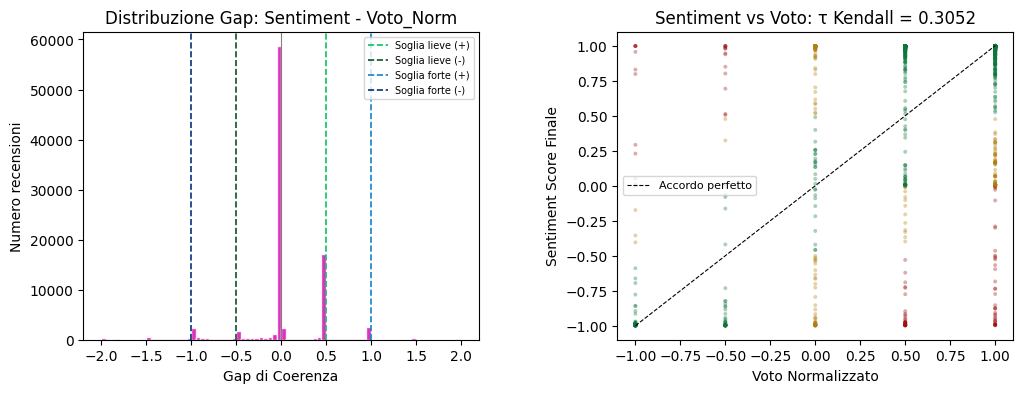

In [23]:
# Visualizzazioni grafiche
fig = plt.figure(figsize=(12, 4))
gs  = gridspec.GridSpec(1, 2, figure=fig, wspace=0.35)

# Grafico 1: distribuzione del Gap
ax1 = fig.add_subplot(gs[0])
gap_validi = df_testo['Gap_Coerenza'].dropna()
ax1.hist(gap_validi, bins=80, color="#d70eb3", edgecolor='white', alpha=0.85)
ax1.axvline( 0.5, color="#0bc260", linestyle='--', linewidth=1.2, label='Soglia lieve (+)')
ax1.axvline(-0.5, color="#0a5324", linestyle='--', linewidth=1.2, label='Soglia lieve (-)')
ax1.axvline( 1.0, color="#1184c6", linestyle='--', linewidth=1.2, label='Soglia forte (+)')
ax1.axvline(-1.0, color="#05317c", linestyle='--', linewidth=1.2, label='Soglia forte (-)')
ax1.axvline( 0.0, color='grey',    linestyle='-',  linewidth=0.8)
ax1.set_xlabel("Gap di Coerenza")
ax1.set_ylabel("Numero recensioni")
ax1.set_title("Distribuzione Gap: Sentiment - Voto_Norm")
ax1.legend(fontsize=7)

# Grafico 2: sentiment vs voto normalizzato
ax2 = fig.add_subplot(gs[1])
campione_scatter = df_testo[df_testo['Sentiment_Score_Finale'].notna() & df_testo['Voto_Norm'].notna()].sample(3000, random_state=42)   # campione per non appesantire il grafico
colori_scatter = campione_scatter['Flag_Coerenza'].map({
    'coerente':               "#0d773b",
    'disallineamento_lieve':  "#b27e0d",
    'disallineamento_forte':  "#9f1111",
    'nd':                     '#cccccc'})

ax2.scatter(campione_scatter['Voto_Norm'], campione_scatter['Sentiment_Score_Finale'], c=colori_scatter, alpha=0.35, s=8, linewidths=0)
ax2.plot([-1,1], [-1,1], 'k--', linewidth=0.8, label='Accordo perfetto')
ax2.set_xlabel("Voto Normalizzato")
ax2.set_ylabel("Sentiment Score Finale")
ax2.set_title(f"Sentiment vs Voto: τ Kendall = {tau:.4f}")
ax2.legend(fontsize=8)

plt.show()

In [24]:
# Ispezione visiva: casi estremi di disallineamento
# Disallineamento Positivo forte: testo molto positivo, voto molto basso.
dis_pos = df_testo[(df_testo['Direzione_Gap'] == 'disallineamento_positivo') & (df_testo['Flag_Coerenza'] == 'disallineamento_forte')].nlargest(4, 'Gap_Coerenza')
display(HTML("<b>Testo più positivo del voto</b>"))
with pd.option_context('display.max_colwidth', 120):
    display(dis_pos[['Corpus_Sentiment', 'Voto Generale Recensione', 'Sentiment_Score_Finale', 'Voto_Norm', 'Gap_Coerenza']])

# Disallineamento Negativo forte: testo molto negativo, voto molto alto.
dis_neg = df_testo[(df_testo['Direzione_Gap'] == 'disallineamento_negativo') & (df_testo['Flag_Coerenza'] == 'disallineamento_forte')].nsmallest(4, 'Gap_Coerenza')
display(HTML("<b>Testo più negativo del voto</b>"))
with pd.option_context('display.max_colwidth', 120):
    display(dis_neg[['Corpus_Sentiment', 'Voto Generale Recensione', 'Sentiment_Score_Finale', 'Voto_Norm', 'Gap_Coerenza']])

,Corpus_Sentiment,Voto Generale Recensione,Sentiment_Score_Finale,Voto_Norm,Gap_Coerenza
ID Recensione,,,,,
10271559-25bv-itIT-2017-011911430000,perfetta Facilità di montaggio esteticamente molto bella e ottimo rapporto qualità prezzo,1,0.9986,-1.0,1.9986
27045451-1yoi-tIT2-0210-626T17000800,Specchiarsi Il prodotto è perfettamente adeguato alla sua destinazione nella casa ( camera di mio figlio) ; non ingo...,1,0.9985,-1.0,1.9985
41804110-4yoi-tIT2-0221-112T11002000,Bella e funzionale,1,0.9985,-1.0,1.9985
10466707-05bv-itIT-2018-062919360360,Ho comprato questo prodotto due mesi fa e sono molto contento,1,0.9985,-1.0,1.9985


,Corpus_Sentiment,Voto Generale Recensione,Sentiment_Score_Finale,Voto_Norm,Gap_Coerenza
ID Recensione,,,,,
f8356ce3-c6f8-4fc6-b0dd-d8e485d8cf24,Difettoso L’appendiabiti è di ottima fattura ma purtroppo il piolino dell’asta che modifica l’altezza è difettoso e ...,5,-0.9981,1.0,-1.9981
28830308-4yoi-tIT2-0210-906T06232200,Prodotto sufficiente Mi aspettavo gli stessi innesti delle mensole lack piu lunghe. Un po deluso dal metodo di fissa...,5,-0.9981,1.0,-1.9981
36543044-3e1b-43a3-b951-d85dcffc505f,Non adatto ai due cestini Ho sostituito il vecchio Utrusta con questo nuovo. Purtroppo non è risultato altrettanto v...,5,-0.9981,1.0,-1.9981
45987233-0yoi-tIT2-0230-411T11323900,Cassettiera molto spaziosa Piccolo prezzo per questa cassettiera davvero capiente. Ho rivalutato molto i prodotti ik...,5,-0.9981,1.0,-1.9981


## **Conclusioni e Salvataggio**

In [25]:
list(df_testo.columns)

['Numero Articolo Catalogo',
 'Testo Tradotto',
 'Voto Generale Recensione',
 'Raccomandato',
 'Voto: Estetica',
 'Voto: Facilità di montaggio/installazione',
 'Voto: Come valuti la qualità del prodotto?',
 'Voto: Rapporto qualità/prezzo',
 'Voto: Soddisfa le mie aspettative',
 'Voto: Aiuta a risparmiare energia e/o acqua',
 'Voto: Aiuta a ridurre/differenziare i rifiuti',
 'Lista_Emoji',
 'Emoji_Pos',
 'Emoji_Neg',
 'Emoji_Neu',
 'Emoji_Score_Novak',
 'Testo_Senza_Emoji',
 'Corpus_Sentiment',
 'Sentiment_VADER',
 'Voto_Num',
 'Sentiment_BERT_Soft',
 'P_pos_BERT',
 'P_neu_BERT',
 'P_neg_BERT',
 'Sentiment_FEELIT',
 'P_pos_FEELIT',
 'P_neg_FEELIT',
 'Sentiment_Score',
 'Score_Integrato_1',
 'Score_Integrato_2',
 'Score_Integrato_3',
 'Sentiment_Score_Finale',
 'Voto_Norm',
 'Gap_Coerenza',
 'Flag_Coerenza',
 'Direzione_Gap']

Prima di salvare, **aggregiamo la colonna inerente ai disallineamenti** (Flag_Coerenza) **per il voto**, così da vedere se ci sono discordanze forti che si concentrano su voti specifici. Analizziamo, quindi, per ogni livello di voto, quante recensioni (in proporzione) cadono in ciascuna classe di coerenza (i valori sommano a 1 per riga). L'ipotesi è che i voti intermedi (3 stelle) possano produrre più incoerenza.

In [26]:
df_testo[df_testo['Flag_Coerenza'] != 'nd'].groupby('Voto Generale Recensione')['Flag_Coerenza'].value_counts(normalize=True).unstack()

Flag_Coerenza,coerente,disallineamento_forte,disallineamento_lieve
Voto Generale Recensione,,,
1,0.837572,0.112241,0.050187
2,0.762523,0.181354,0.056122
3,0.141781,NaN,0.858219
4,0.927485,0.050585,0.021930
5,0.942929,0.019745,0.037326


Per ogni livello di voto, si **incrociano Flag_Coerenza e Direzione_Gap**. L'obiettivo è capire non solo quante recensioni si disallineano, ma in quale direzione va il disallineamento: il testo è più positivo o più negativo del voto assegnato?

In [27]:
display(HTML("<h3>Analisi Dettagliata: Coerenza e Direzione per Voto</h3>"))

df_validi = df_testo[df_testo['Voto Generale Recensione'].notna() & df_testo['Flag_Coerenza'].notna() & (df_testo['Flag_Coerenza'] != 'nd') & df_testo['Direzione_Gap'].notna() & (df_testo['Direzione_Gap'] != 'nd')].copy()
ordine_flag = ['coerente', 'disallineamento_lieve', 'disallineamento_forte']
ordine_dir  = ['coerente', 'disallineamento_positivo', 'disallineamento_negativo']
ordine_voti = [1, 2, 3, 4, 5]

df_validi['Flag_Coerenza'] = pd.Categorical(df_validi['Flag_Coerenza'], categories=ordine_flag, ordered=True)
df_validi['Direzione_Gap'] = pd.Categorical(df_validi['Direzione_Gap'], categories=ordine_dir, ordered=True)

tabella = (df_validi.groupby(['Voto Generale Recensione', 'Flag_Coerenza', 'Direzione_Gap'], observed=True).size().reset_index(name='N'))

totale_per_voto = df_validi.groupby('Voto Generale Recensione').size().rename('Tot')
tabella = tabella.merge(totale_per_voto, on='Voto Generale Recensione')
tabella['%_sul_voto'] = (tabella['N'] / tabella['Tot'] * 100).round(2)
tabella = tabella.drop(columns='Tot')

# Palette: (sfondo, testo) per ciascuna combinazione Flag × Direzione
palette_righe = {
    ('coerente',              'coerente'):                 ('#054920', '#ffffff'),
    ('disallineamento_lieve', 'disallineamento_positivo'): ("#66A6CC", '#ffffff'),
    ('disallineamento_lieve', 'disallineamento_negativo'): ('#043856', '#ffffff'),
    ('disallineamento_forte', 'disallineamento_positivo'): ("#b15a5a", '#ffffff'),
    ('disallineamento_forte', 'disallineamento_negativo'): ("#670D0D", '#ffffff'),}

def stile_riga(row):
    bg, fg = palette_righe.get((row.name[0], row.name[1]), ('#ffffff', '#000000'))
    return [f'background-color: {bg}; color: {fg}'] * len(row)

for voto in ordine_voti:
    sub = tabella[tabella['Voto Generale Recensione'] == voto].copy()
    if sub.empty:
        continue
    n_tot_voto = df_validi[df_validi['Voto Generale Recensione'] == voto].shape[0]
    display(HTML(f"<h4>Voto {int(voto)} - {n_tot_voto:,} recensioni totali</h4>"))

    sub_display = sub[['Flag_Coerenza', 'Direzione_Gap', 'N', '%_sul_voto']].set_index(['Flag_Coerenza', 'Direzione_Gap'])
    display(sub_display.style.apply(stile_riga, axis=1).format({'%_sul_voto': '{:.2f}%'}))

,,N,%_sul_voto
Flag_Coerenza,Direzione_Gap,,
coerente,coerente,2470,83.76%
disallineamento_lieve,disallineamento_positivo,148,5.02%
disallineamento_forte,disallineamento_positivo,331,11.22%


,,N,%_sul_voto
Flag_Coerenza,Direzione_Gap,,
coerente,coerente,1644,76.25%
disallineamento_lieve,disallineamento_positivo,121,5.61%
disallineamento_forte,disallineamento_positivo,391,18.14%


,,N,%_sul_voto
Flag_Coerenza,Direzione_Gap,,
coerente,coerente,19582,92.75%
disallineamento_lieve,disallineamento_negativo,463,2.19%
disallineamento_forte,disallineamento_negativo,1068,5.06%


,,N,%_sul_voto
Flag_Coerenza,Direzione_Gap,,
coerente,coerente,61462,94.29%
disallineamento_lieve,disallineamento_negativo,2433,3.73%
disallineamento_forte,disallineamento_negativo,1287,1.97%


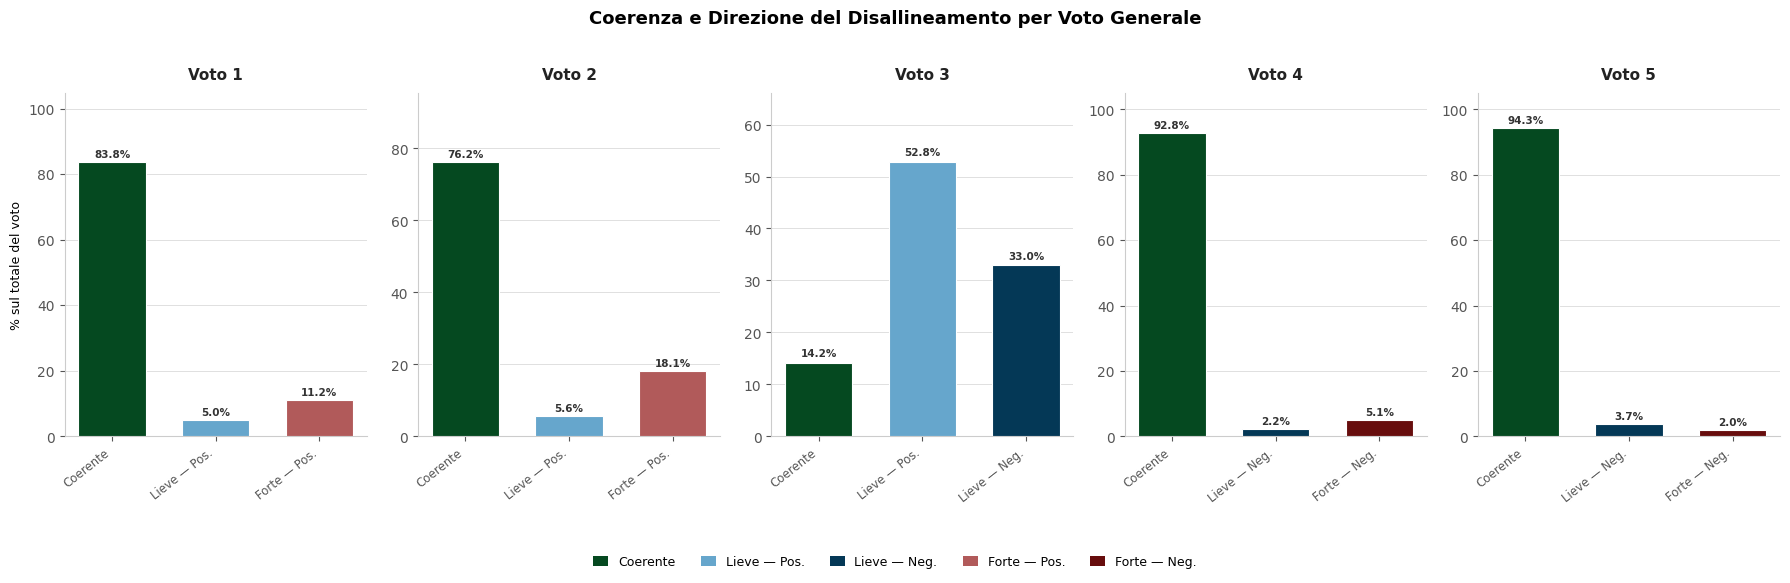

In [28]:
# Grafico
display(HTML("<h3>Distribuzione Coerenza e Direzione per Voto</h3>"))

from matplotlib.patches import Patch

palette = {
    ('coerente',               'coerente'):                "#054920",
    ('disallineamento_lieve',  'disallineamento_positivo'): "#66A6CC",
    ('disallineamento_lieve',  'disallineamento_negativo'): '#043856',
    ('disallineamento_forte',  'disallineamento_positivo'): "#b15a5a",
    ('disallineamento_forte',  'disallineamento_negativo'): "#670D0D",}

etichette_brevi = {
    ('coerente',               'coerente'):                'Coerente',
    ('disallineamento_lieve',  'disallineamento_positivo'): 'Lieve — Pos.',
    ('disallineamento_lieve',  'disallineamento_negativo'): 'Lieve — Neg.',
    ('disallineamento_forte',  'disallineamento_positivo'): 'Forte — Pos.',
    ('disallineamento_forte',  'disallineamento_negativo'): 'Forte — Neg.',}

ordine_chiavi = list(etichette_brevi.keys())

fig, axes = plt.subplots(1, 5, figsize=(18, 5), sharey=False)
fig.patch.set_facecolor('white')

for ax, voto in zip(axes, ordine_voti):
    sub = tabella[tabella['Voto Generale Recensione'] == voto].copy()
    sub['chiave']    = list(zip(sub['Flag_Coerenza'], sub['Direzione_Gap']))
    sub['etichetta'] = sub['chiave'].map(etichette_brevi)
    sub['colore']    = sub['chiave'].map(palette)
    sub['ordine']    = sub['chiave'].map({k: i for i, k in enumerate(ordine_chiavi)})
    sub = sub.sort_values('ordine')

    x = range(len(sub))
    bars = ax.bar(x, sub['%_sul_voto'], color=sub['colore'].fillna('#cccccc'), edgecolor='white', linewidth=0.8, width=0.65, zorder=3)

    # Griglia orizzontale leggera sotto le barre
    ax.yaxis.grid(True, color='#e0e0e0', linewidth=0.7, zorder=0)
    ax.set_axisbelow(True)

    # Etichetta percentuale sopra ogni barra (solo se > 1%)
    for bar, pct in zip(bars, sub['%_sul_voto']):
        if pct > 1:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8, f'{pct:.1f}%', ha='center', va='bottom', fontsize=7.5, color='#333333', fontweight='bold')

    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels(sub['etichetta'], rotation=38, ha='right', fontsize=8.5)
    ax.set_title(f'Voto {int(voto)}', fontweight='bold', fontsize=11, pad=10, color='#222')
    ax.set_ylabel('% sul totale del voto' if voto == 1 else '', fontsize=9)
    ax.set_ylim(0, min(max(sub['%_sul_voto'].max() * 1.25, 15), 105))

    # Bordi puliti
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#cccccc')
    ax.spines['bottom'].set_color('#cccccc')
    ax.tick_params(axis='both', colors='#555555')

# Legenda centrale
legenda = [Patch(facecolor=palette[k], label=etichette_brevi[k], linewidth=0) for k in ordine_chiavi]
fig.legend(handles=legenda, loc='lower center', ncol=5, fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.12), handlelength=1.2, handleheight=0.9)

plt.suptitle('Coerenza e Direzione del Disallineamento per Voto Generale', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# SALVATAGGIO FINALE

# Colonne ESCLUSE dal dataset finale:
#   - Segnale emoji grezzo: Lista_Emoji, Emoji_Pos, Emoji_Neg, Emoji_Neu, Emoji_Score_Novak
#   - Testo intermedio: Testo_Senza_Emoji (colonna di pre-processing, non più necessaria)
#   - Probabilità grezze BERT: P_pos_BERT, P_neu_BERT, P_neg_BERT (diagnostica, non analiticamente rilevanti)
#   - Score intermedi: Sentiment_VADER, Sentiment_BERT_Soft, Sentiment_FEELIT (sostituiti da Sentiment_Score_Finale)
#   - Score integrati: Score_Integrato_1, Score_Integrato_2, Score_Integrato_3 (non migliorativi, Δρ < 0.01)
#   - Colonne di supporto: Voto_Num (ridondante con Voto Generale Recensione), Voto_Norm (ridondante)
#   - Sentiment_Score (identico a Sentiment_Score_Finale nel caso corrente, dove le emoji non sono state integrate)

if df_testo['Sentiment_Score_Finale'].equals(df_testo['Sentiment_Score']):
    print("Verifica: Sentiment_Score_Finale coincide con Sentiment_Score (emoji non integrate, Δρ < 0.01).")
else:
    print("Verifica: Sentiment_Score_Finale include l'integrazione emoji selezionata nel Paragrafo 5.2.")

n_gap = df_testo['Gap_Coerenza'].notna().sum()
assert df_testo['Gap_Coerenza'].dropna().between(-2, 2).all(), "ATTENZIONE: gap fuori dal range teorico [-2, +2]."
print(f"Verifica: {n_gap:,} gap validi nel range teorico [-2, +2]; {df_testo['Gap_Coerenza'].isna().sum():,} ghost review a NaN.")

# Colonne INCLUSE nel dataset finale
colonne_finali = [
    'Numero Articolo Catalogo',
    'Testo Tradotto',
    'Voto Generale Recensione',
    'Raccomandato',
    'Voto: Estetica',
    'Voto: Facilità di montaggio/installazione',
    'Voto: Come valuti la qualità del prodotto?',
    'Voto: Rapporto qualità/prezzo',
    'Voto: Soddisfa le mie aspettative',
    'Voto: Aiuta a risparmiare energia e/o acqua',
    'Voto: Aiuta a ridurre/differenziare i rifiuti',
    'Corpus_Sentiment',
    'Sentiment_Score_Finale',
    'Gap_Coerenza',
    'Flag_Coerenza',
    'Direzione_Gap',]

# Sicurezza: filtra sulle colonne effettivamente presenti
colonne_presenti  = [c for c in colonne_finali if c in df_testo.columns]
colonne_mancanti  = [c for c in colonne_finali if c not in df_testo.columns]
if colonne_mancanti:
    print(f"ATTENZIONE: colonne non trovate nel dataframe: {colonne_mancanti}")

percorso_output = Path("Circular Second Hand") / "Analisi" / "Analisi - Recensioni" / "Risultati Analisi - Recensioni" / "3_nlp_sentiment__recensioni.csv"

# index=True: ID Recensione è l'indice del dataframe e va preservato come prima colonna del CSV
df_testo[colonne_presenti].to_csv(percorso_output, index=True, encoding='utf-8-sig')

display(HTML(f"""<h4>Salvataggio completato: <code>3_nlp_sentiment__recensioni.csv</code></h4>
    <ul>
      <li>Righe: <b>{len(df_testo):,}</b>.</li>
      <li>Colonne salvate: <b>{len(colonne_presenti)}</b> (+ indice ID Recensione).</li>
      <li>Percorso: <code>{percorso_output}</code>.</li>
    </ul>"""))

Verifica: Sentiment_Score_Finale coincide con Sentiment_Score (emoji non integrate, Δρ < 0.01).
Verifica: 97,240 gap validi nel range teorico [-2, +2]; 300 ghost review a NaN.


In [30]:
df_colonne = df_testo[colonne_presenti].reset_index()
display(df_colonne.head(3))

,ID Recensione,Numero Articolo Catalogo,Testo Tradotto,Voto Generale Recensione,Raccomandato,Voto: Estetica,Voto: Facilità di montaggio/installazione,Voto: Come valuti la qualità del prodotto?,Voto: Rapporto qualità/prezzo,Voto: Soddisfa le mie aspettative,Voto: Aiuta a risparmiare energia e/o acqua,Voto: Aiuta a ridurre/differenziare i rifiuti,Corpus_Sentiment,Sentiment_Score_Finale,Gap_Coerenza,Flag_Coerenza,Direzione_Gap
0,32964456-8yoi-tIT2-0220-116T15305800,438360,"Comodissimo Tanto comodo che ""rapisce""!\nSempl...",5,True,5.0,5.0,5.0,5.0,5.0,NaN,NaN,"Comodissimo Tanto comodo che ""rapisce""! Sempli...",0.9979,-0.0021,coerente,coerente
1,38622991-7yoi-tIT2-0220-718T09510900,10243296,ok ok,5,True,5.0,5.0,5.0,5.0,5.0,NaN,NaN,ok ok,0.0648,-0.9352,disallineamento_lieve,disallineamento_negativo
2,20875570-3yoi-tIT2-0201-027T18251500,10243296,praticità comodo e pratico si inserisce bene i...,4,True,5.0,5.0,4.0,4.0,5.0,NaN,NaN,praticità comodo e pratico si inserisce bene i...,0.9975,0.4975,coerente,coerente
